# Item-Based Collaborative Filtering pada MovieLens

Notebook ini memprediksi rating dan membuat daftar Top-N film dengan item-based CF pada ml-latest-small. Prediksi rating dinilai dengan MAE, MSE, RMSE, dan NMSE. Top-N dinilai dengan NDCG@N. Top-N diambil dari prediksi rating yang sama: semua film yang belum dirating user diprediksi, diurutkan, lalu N teratas dipakai.

Data dibagi 80/20 dengan seed 42, menghasilkan train 80.669 dan test 20.167.

Definisinya mengacu pada materi kuliah M03 (Item-Based CF) dan Jannach dkk. (2010):

* Similarity antar film dihitung dari user yang merating kedua film. Ada dua varian: cosine, dan adjusted cosine (rating dikurangi rata-rata user).
* Prediksi: `pred(u,p) = Σ sim(i,p)·r_ui / Σ sim(i,p)`, dijumlahkan atas film yang sudah dirating user u dan mirip dengan film p.
* Threshold similarity: nilainya 0, jadi semua film dengan sim positif ikut.

Urutan notebook: setup, preprocessing dan split, struktur data dari sisi item, model ItemCF (dengan contoh Alice dan satu prediksi yang dirinci), baseline dan metrik, evaluasi rating, Top-N dan NDCG, contoh Top-N, ringkasan.

## Ringkasan parameter dan metrik

| Parameter | Nilai | Keterangan |
|---|---|---|
| `SEED` | 42 | Split dan tie-break |
| `TEST_SIZE` | 0,2 | Train 80.669, test 20.167 |
| `SIM_THRESHOLD` | 0,0 | Hanya film dengan sim > 0 yang ikut prediksi |
| `N_LIST` | [5, 10] | Panjang daftar Top-N untuk NDCG@N |
| `REL_THRESHOLD` | 4,0 | Film relevan bila rating ≥ 4 (NDCG biner) |
| `MIN_NEIGH_TOPN` | 5 | Minimal film mirip agar masuk Top-N |
| `DEMO_USER_IDS` | [43] | User untuk contoh Top-N (5 film) |

Metrik rating: MAE = rata-rata abs(p − y), MSE = rata-rata (p − y)², RMSE = √MSE, dan NMSE = MSE / (r_max − r_min), yaitu MSE / 4,5. Makin kecil makin baik.

Metrik Top-N: `DCG = Σ rel_i / log2(i+1)` dan `nDCG = DCG / IDCG`. Makin besar makin baik. Versi linear memakai rating sebagai rel. Versi biner memakai 1 bila rating ≥ 4, selain itu 0. Yang diurutkan adalah film test milik tiap user, dan hanya user dengan minimal 2 film test yang dihitung.

Coverage adalah persentase pasangan test yang punya minimal satu film mirip. Sisanya memakai rata-rata user.

## 0. Setup & parameter

In [1]:
import os, gc, copy, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 40)

if not os.path.exists("ml-latest-small/ratings.csv"):
    !wget -q https://files.grouplens.org/datasets/movielens/ml-latest-small.zip
    !unzip -q -o ml-latest-small.zip
print(os.listdir("ml-latest-small"))

['movies.csv', 'ratings.csv', 'tags.csv', 'README.txt', 'links.csv']


In [2]:
SEED          = 42
TEST_SIZE     = 0.2
N_LIST        = [5, 10]
REL_THRESHOLD = 4.0
MIN_NEIGH_TOPN = 5        # minimal film mirip agar masuk Top-N

# Hanya film dengan sim > threshold yang ikut prediksi. 0 = semua sim positif.
SIM_THRESHOLD = 0.0

DEMO_MODEL    = "ItemCF cosine"   # model untuk contoh Top-N
DEMO_USER_IDS = [43]              # userId asli MovieLens untuk contoh Top-N

rng_global = np.random.default_rng(SEED)

BLUE, ORANGE, AQUA, GRAY = "#2a78d6", "#eb6834", "#1baf7a", "#9a9a95"
INK, INK2 = "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": GRAY, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "axes.titleweight": "bold", "axes.titlesize": 11, "axes.grid": True, "grid.color": "#e6e6e3",
    "grid.linewidth": 0.6, "axes.axisbelow": True, "legend.frameon": False,
})

## 1. Preprocessing & split

Split 80/20 acak dengan seed tetap. Dua puluh persen rating disembunyikan dari model. Itulah "sel kosong" yang nanti diprediksi dan dicocokkan dengan rating aslinya. Rata-rata user dan similarity hanya dihitung dari train supaya tidak ada kebocoran data.

Pada dataset asli, ukuran train dan test harus 80.669 dan 20.167. Kalau berbeda, berarti splitnya tidak sama dengan split 80/20 seed 42.

In [3]:
ratings = pd.read_csv("ml-latest-small/ratings.csv")
movies  = pd.read_csv("ml-latest-small/movies.csv")
print("ratings.shape =", ratings.shape, "| movies.shape =", movies.shape)

print("Missing per kolom:\n", ratings.isna().sum().to_string())
dups = ratings.duplicated(subset=["userId", "movieId"]).sum()
print("\nDuplikat (userId, movieId):", dups)
ratings = ratings.drop_duplicates(subset=["userId", "movieId"]).drop(columns=["timestamp"])

ukuran_data = (ratings.userId.nunique(), ratings.movieId.nunique(), len(ratings))

uid = {u: i for i, u in enumerate(sorted(ratings.userId.unique()))}
iid = {m: i for i, m in enumerate(sorted(ratings.movieId.unique()))}
ratings["u"] = ratings.userId.map(uid)
ratings["i"] = ratings.movieId.map(iid)
N_U, N_I = len(uid), len(iid)
inv_iid = {v: k for k, v in iid.items()}
R_MIN, R_MAX = float(ratings.rating.min()), float(ratings.rating.max())
print(f"\nN_U={N_U}, N_I={N_I}, rating {R_MIN}-{R_MAX}, rmax-rmin={R_MAX-R_MIN}")
print(f"Sparsity = {(1 - len(ratings) / (N_U * N_I)) * 100:.2f}%")

ratings.shape = (100836, 4) | movies.shape = (9742, 3)
Missing per kolom:
 userId       0
movieId      0
rating       0
timestamp    0

Duplikat (userId, movieId): 0

N_U=610, N_I=9724, rating 0.5-5.0, rmax-rmin=4.5
Sparsity = 98.30%


In [4]:
def split_df(df, test_size, seed):
    perm = np.random.default_rng(seed).permutation(len(df))
    n_test = int(round(len(df) * test_size))
    return df.iloc[perm[n_test:]].reset_index(drop=True), df.iloc[perm[:n_test]].reset_index(drop=True)

train_df, test_df = split_df(ratings[["u", "i", "rating"]], TEST_SIZE, SEED)
print("train:", train_df.shape, "| test:", test_df.shape)

if ukuran_data == (610, 9724, 100836):      # dataset asli ml-latest-small
    assert len(train_df) == 80669 and len(test_df) == 20167, "Split TIDAK sama dengan split 80/20 seed 42!"
    print("OK: split sesuai (80.669 / 20.167).")
else:
    print("PERINGATAN: ukuran data tidak sama dengan ml-latest-small asli.")

overlap = pd.merge(train_df[["u", "i"]], test_df[["u", "i"]], on=["u", "i"]).shape[0]
print("Pasangan (user,item) yang muncul di train DAN test:", overlap, "(harus 0)")
print("User di test tapi tidak punya rating di train:", len(set(test_df.u) - set(train_df.u)))
print("Item di test yang belum pernah ada di train (cold item):",
      f"{(~test_df.i.isin(train_df.i)).mean()*100:.2f}% dari pasangan test")

train: (80669, 3) | test: (20167, 3)
OK: split sesuai (80.669 / 20.167).
Pasangan (user,item) yang muncul di train DAN test: 0 (harus 0)
User di test tapi tidak punya rating di train: 0
Item di test yang belum pernah ada di train (cold item): 3.96% dari pasangan test


## 2. Struktur data dari sisi item

Item-based CF membandingkan kolom (film), bukan baris (user). Similarity dua film hanya bisa dihitung dari user yang merating keduanya, jadi film yang jarang dirating sulit punya tetangga. Di MovieLens kebanyakan film memang hanya punya sedikit rating, jadi saya ukur dulu seberapa banyak.

,% film (katalog),% pasangan test
rating film di train,,
0 (cold item),7.5,4.0
1-4,59.3,10.1
5-19,22.5,24.6
20-49,7.5,28.1
>=50,3.2,33.2


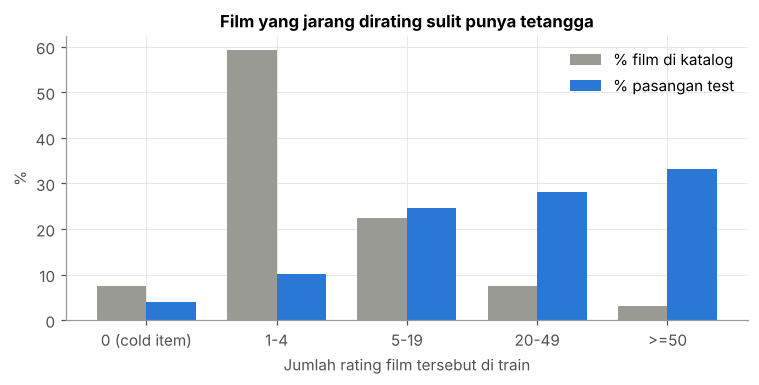

In [5]:
item_cnt_train = np.bincount(train_df.i.values, minlength=N_I)          # jumlah rating tiap film di train
sup_test = item_cnt_train[test_df.i.values]                               # dukungan item untuk tiap pasangan test
BUCKET_BINS   = [-1, 0, 4, 19, 49, 10**9]
BUCKET_LABELS = ["0 (cold item)", "1-4", "5-19", "20-49", ">=50"]

b_items = pd.Series(pd.cut(item_cnt_train, BUCKET_BINS, labels=BUCKET_LABELS)).value_counts(normalize=True).reindex(BUCKET_LABELS)
b_test  = pd.Series(pd.cut(sup_test,       BUCKET_BINS, labels=BUCKET_LABELS)).value_counts(normalize=True).reindex(BUCKET_LABELS)
support = pd.DataFrame({"% film (katalog)": b_items * 100, "% pasangan test": b_test * 100}).round(1)
support.index.name = "rating film di train"
display(support)

fig, ax = plt.subplots(figsize=(7, 3.6))
x = np.arange(len(BUCKET_LABELS)); w = 0.38
ax.bar(x - w/2, support["% film (katalog)"], w, color=GRAY, label="% film di katalog")
ax.bar(x + w/2, support["% pasangan test"], w, color=BLUE, label="% pasangan test")
ax.set_xticks(x); ax.set_xticklabels(BUCKET_LABELS)
ax.set(xlabel="Jumlah rating film tersebut di train", ylabel="%", title="Film yang jarang dirating sulit punya tetangga")
ax.legend()
plt.tight_layout(); plt.savefig("fig_i01_item_support.png", dpi=200, bbox_inches="tight"); plt.show()

## 3. Model Item-Based CF

Cara prediksi `pred(u,p)`:

1. Similarity antar film dihitung sekali untuk semua pasangan lewat perkalian matriks, tanpa `fillna(0)` dan tanpa loop. Norma di penyebut hanya memakai user yang merating kedua film, seperti contoh hitung manual `sqrt(25+9+1) * sqrt(4+9+9)`.
   * `cosine` memakai rating apa adanya.
   * `adjusted` mengurangi rata-rata user (dari seluruh rating user di train), lalu dihitung seperti cosine.
2. Film mirip adalah film yang sudah dirating user u dengan sim > `SIM_THRESHOLD`. Nilainya 0, jadi semua film dengan sim positif ikut. Nilai ini bisa diubah di sel parameter.
3. Prediksi memakai rumus dasar `pred(u,p) = Σ sim(i,p)·r_ui / Σ sim(i,p)` atas film mirip.

4. Kalau tidak ada film mirip (misalnya film belum pernah dirating di train), prediksinya memakai rata-rata user. Saya pilih ini karena rata-rata user ada untuk semua user, sedangkan rata-rata film tidak ada untuk film tanpa rating.
5. Prediksi dipotong ke [0,5; 5].

Top-N tidak punya rumus khusus. Skor tiap film kandidat adalah prediksi yang sama, lalu diurutkan menurun dan dipotong N.

Similarity dan rata-rata hanya dari train. Matriks similarity 9.724 × 9.724 disimpan sebagai `float32` (sekitar 380 MB) dan dihitung per blok supaya muat di RAM Colab.

In [6]:
class ItemCF:
    # similarity: "cosine" (rating apa adanya) atau "adjusted" (adjusted cosine: rating - rata-rata user)
    # threshold : hanya item dengan sim > threshold yang ikut prediksi
    def __init__(self, similarity="cosine", threshold=0.0, r_min=0.5, r_max=5.0, block=1000):
        self.similarity, self.threshold = similarity, threshold
        self.r_min, self.r_max, self.block = r_min, r_max, block

    def fit(self, train_df, n_users, n_items):
        u, i = train_df.u.values, train_df.i.values
        r = train_df.rating.values.astype(np.float32)
        R = np.zeros((n_users, n_items), np.float32); M = np.zeros((n_users, n_items), np.float32)
        R[u, i] = r; M[u, i] = 1.0
        ucnt, icnt = M.sum(1), M.sum(0)
        self.n_items, self.item_cnt = n_items, icnt
        self.global_mean = float(r.mean())
        # rata-rata hanya dari train
        self.user_mean = np.where(ucnt > 0, R.sum(1) / np.maximum(ucnt, 1), self.global_mean).astype(np.float32)
        # daftar item yang dirating tiap user (dipakai saat prediksi)
        order = np.lexsort((i, u))
        us, its, rs = u[order], i[order], r[order]
        bounds = np.searchsorted(us, np.arange(n_users + 1))
        self.u_items = [its[bounds[x]:bounds[x + 1]] for x in range(n_users)]
        self.u_vals  = [rs[bounds[x]:bounds[x + 1]] for x in range(n_users)]
        X = R if self.similarity == "cosine" else (R - self.user_mean[:, None]) * M   # 0 bila kosong
        self.sim = self._similarity(X, M)
        return self

    def _similarity(self, X, M):
        n_items = X.shape[1]
        X2 = X * X
        A = X2.T @ M                       # A[i,j] = sum_u x_ui^2 * [u juga merating j]  (norma i atas user co-rated i-j)
        sim = np.zeros((n_items, n_items), np.float32)
        for a in range(0, n_items, self.block):
            b = slice(a, min(a + self.block, n_items))
            num = X[:, b].T @ X                                  # sum_u x_ui * x_uj (hanya user co-rated yang menyumbang)
            den = np.sqrt(A[b] * A[:, b].T)                      # sqrt( sum_co x_ui^2 * sum_co x_uj^2 )
            s = np.divide(num, den, out=np.zeros_like(num), where=den > 1e-12)
            sim[b] = np.clip(s, -1, 1)
        del A
        np.fill_diagonal(sim, 0.0)
        return sim

    def _predict_user_multi(self, u, items, thresholds, chunk=2000):
        # prediksi untuk beberapa threshold sekaligus (similarity diambil sekali)
        J, rv = self.u_items[u], self.u_vals[u]
        out = {t: np.full(len(items), self.user_mean[u], dtype=float) for t in thresholds}
        nn = {t: np.zeros(len(items), dtype=int) for t in thresholds}
        if len(J) == 0:
            return out, nn
        for a in range(0, len(items), chunk):
            I = items[a:a + chunk]
            S = self.sim[np.ix_(I, J)]
            for t in thresholds:
                W = np.where(S > t, S, 0.0)
                den = W.sum(1); has = den > 0
                val = np.divide(W @ rv, den, out=np.zeros(len(I)), where=has)
                out[t][a:a + chunk] = np.where(has, val, self.user_mean[u])   # tidak ada item mirip -> back-off rata-rata user
                nn[t][a:a + chunk] = (W > 0).sum(1)
        return out, nn

    def predict_pairs_multi(self, users, items, thresholds, clip=True):
        users, items = np.asarray(users), np.asarray(items)
        pred = {t: np.empty(len(users)) for t in thresholds}; nn = {t: np.zeros(len(users), dtype=int) for t in thresholds}
        for u, pos in pd.Series(np.arange(len(users))).groupby(users).indices.items():
            o, n_ = self._predict_user_multi(u, items[pos], thresholds)
            for t in thresholds:
                pred[t][pos], nn[t][pos] = o[t], n_[t]
        if clip:
            pred = {t: np.clip(v, self.r_min, self.r_max) for t, v in pred.items()}
        return pred, nn

    def predict_pairs(self, users, items, threshold=None, clip=True):
        t = self.threshold if threshold is None else threshold
        p, n = self.predict_pairs_multi(users, items, [t], clip)
        return p[t], n[t]

    def recommend(self, u, N, exclude_items, threshold=None, min_neigh=1):
        t = self.threshold if threshold is None else threshold
        cand = np.setdiff1d(np.arange(self.n_items), np.asarray(list(exclude_items)))
        o, n_ = self._predict_user_multi(u, cand, [t])
        raw, nn = o[t], n_[t]
        ok = nn >= min_neigh
        cand, raw, nn = cand[ok], raw[ok], nn[ok]
        top = np.argsort(-raw, kind="stable")[:N]
        return pd.DataFrame({"i": cand[top], "pred": np.clip(raw[top], self.r_min, self.r_max),
                             "pred_unclipped": raw[top], "n_neighbors": nn[top]})

### 3.1 Verifikasi dengan contoh Alice

Sebelum dipakai di MovieLens, kode harus menghasilkan angka contoh Alice (5 user × 5 item): similarity cosine `sim(I1,I2)=0,7803`, `sim(I2,I3)=0,9420`, `sim(I1,I3)=0,8198`, `sim(I1,I5)=0,9941`, prediksi Alice–Item5 `4,0752`, dan adjusted cosine `sim(I5,I1)=0,80`.

Contoh acuan tidak memberi prediksi untuk adjusted cosine. Adjusted cosine menghasilkan similarity negatif untuk sebagian film. Kalau semua film ikut dihitung, prediksinya meleset jauh (sekitar 0,05), jadi hanya film dengan sim > threshold (0) yang dipakai, sesuai anjuran memakai threshold similarity.

In [7]:
toy = pd.DataFrame({
    "Item1": [5, 3, 4, 3, 1], "Item2": [3, 1, 3, 3, 5], "Item3": [4, 2, 4, 1, 5],
    "Item4": [4, 3, 3, 5, 2], "Item5": [np.nan, 3, 5, 4, 1]},
    index=["Alice", "User1", "User2", "User3", "User4"])
display(toy)

toy_idx = toy.reset_index(drop=True); toy_idx.columns = range(5)          # baris = user 0..4, kolom = item 0..4
long = toy_idx.stack().dropna().reset_index(); long.columns = ["u", "i", "rating"]   # NaN (Alice-Item5) hilang

m_cos = ItemCF("cosine", threshold=0.0, r_min=1, r_max=5).fit(long, 5, 5)
print("cosine  : sim(I1,I2)=%.4f  sim(I2,I3)=%.4f  sim(I1,I3)=%.4f  sim(I1,I5)=%.4f   <- acuan: 0.7803 0.9420 0.8198 0.9941"
      % (m_cos.sim[0, 1], m_cos.sim[1, 2], m_cos.sim[0, 2], m_cos.sim[0, 4]))
p_cos, nn_cos = m_cos.predict_pairs([0], [4])
print(f"cosine  : pred(Alice, Item5) = {p_cos[0]:.4f} dengan {nn_cos[0]} tetangga   <- acuan: 4.0752")
assert np.allclose([m_cos.sim[0, 1], m_cos.sim[1, 2], m_cos.sim[0, 2], m_cos.sim[0, 4]], [0.7803, 0.9420, 0.8198, 0.9941], atol=1e-3)
assert abs(p_cos[0] - 4.0752) < 1e-3

m_adj = ItemCF("adjusted", threshold=0.0, r_min=1, r_max=5).fit(long, 5, 5)
print("\nrata-rata user (train) =", np.round(m_adj.user_mean, 2), " <- Alice=4.0, User1=2.4, User2=3.8, User3=3.2, User4=2.8")
print("adjusted: sim(I5, I1..I4) =", np.round(m_adj.sim[4, :4], 3), " <- acuan: sim(I5,I1)=0.80")
assert abs(m_adj.sim[4, 0] - 0.80) < 0.01
p_adj, nn_adj = m_adj.predict_pairs([0], [4])
s1, s4 = m_adj.sim[4, 0], m_adj.sim[4, 3]
print(f"adjusted: pred(Alice, Item5) = {p_adj[0]:.3f} dengan {nn_adj[0]} tetangga (sim>0 saja: Item1 dan Item4)")
print(f"          hitung tangan = (5*{s1:.3f} + 4*{s4:.3f}) / ({s1:.3f} + {s4:.3f}) = {(5*s1 + 4*s4)/(s1 + s4):.3f}")
assert abs(p_adj[0] - (5*s1 + 4*s4)/(s1 + s4)) < 1e-3
print("OK: kode mereproduksi contoh acuan.")

,Item1,Item2,Item3,Item4,Item5
Alice,5,3,4,4,NaN
User1,3,1,2,3,3.0
User2,4,3,4,3,5.0
User3,3,3,1,5,4.0
User4,1,5,5,2,1.0


cosine  : sim(I1,I2)=0.7803  sim(I2,I3)=0.9420  sim(I1,I3)=0.8198  sim(I1,I5)=0.9941   <- acuan: 0.7803 0.9420 0.8198 0.9941
cosine  : pred(Alice, Item5) = 4.0752 dengan 4 tetangga   <- acuan: 4.0752

rata-rata user (train) = [4.  2.4 3.8 3.2 2.8]  <- Alice=4.0, User1=2.4, User2=3.8, User3=3.2, User4=2.8
adjusted: sim(I5, I1..I4) = [ 0.805 -0.908 -0.764  0.433]  <- acuan: sim(I5,I1)=0.80
adjusted: pred(Alice, Item5) = 4.650 dengan 2 tetangga (sim>0 saja: Item1 dan Item4)
          hitung tangan = (5*0.805 + 4*0.433) / (0.805 + 0.433) = 4.650
OK: kode mereproduksi contoh acuan.


### 3.2 Satu prediksi dirinci di MovieLens

Ambil satu user dan satu film dari test. Rating aslinya disembunyikan dari model. Tabel menunjukkan film yang sudah dirating user dan mirip dengan film target. Rumus `pred(u,p) = Σ sim·r_ui / Σ sim` dihitung dari tabel itu, lalu hasilnya dibandingkan dengan rating asli.

In [8]:
ITEM_MODELS = {                                       # nama: jenis similarity
    "ItemCF cosine":     "cosine",
    "ItemCF adj-cosine": "adjusted",
}
item_models = {name: ItemCF(simname, threshold=SIM_THRESHOLD, r_min=R_MIN, r_max=R_MAX).fit(train_df, N_U, N_I)
               for name, simname in ITEM_MODELS.items()}

movie_info = movies.set_index("movieId")
inv_uid = {v: k for k, v in uid.items()}
def title_of(i):  return movie_info.loc[inv_iid[i], "title"]
def genres_of(i): return movie_info.loc[inv_iid[i], "genres"]

def explain_prediction(model, u, i, true_rating=None):
    J, rv = model.u_items[u], model.u_vals[u]          # film yang sudah dirating user u di train
    s = model.sim[i, J]
    keep = s > model.threshold
    tbl = pd.DataFrame({"film yang sudah dirating": [title_of(j) for j in J[keep]],
                        "sim ke film target": s[keep], "rating user (r_ui)": rv[keep]})
    tbl["sim x rating"] = tbl["sim ke film target"] * tbl["rating user (r_ui)"]
    tbl = tbl.sort_values("sim ke film target", ascending=False)
    raw = tbl["sim x rating"].sum() / tbl["sim ke film target"].sum()
    pred = float(np.clip(raw, R_MIN, R_MAX))
    print(f"User {inv_uid[u]} | Film target: {title_of(i)}")
    print(f"Jumlah film mirip dipakai   = {len(tbl)}")
    print(f"Σ sim·rating / Σ sim        = {raw:.3f}  -> clip [{R_MIN}, {R_MAX}] = {pred:.3f}")
    if true_rating is not None:
        print(f"Rating asli (disembunyikan) = {true_rating}   | selisih = {abs(pred - true_rating):.3f}")
    assert abs(model.predict_pairs([u], [i])[0][0] - pred) < 1e-3, "hasil tidak sama dengan predict_pairs"
    display(tbl.round(3).reset_index(drop=True).head(10))

# contoh: satu pasangan test yang punya cukup banyak film mirip
m_demo = item_models["ItemCF cosine"]
_, nn_all = m_demo.predict_pairs(test_df.u.values, test_df.i.values)
row = test_df[nn_all >= 5].iloc[0]
explain_prediction(m_demo, int(row.u), int(row.i), true_rating=row.rating)

User 104 | Film target: Kitchen Stories (Salmer fra kjøkkenet) (2003)
Jumlah film mirip dipakai   = 105
Σ sim·rating / Σ sim        = 3.662  -> clip [0.5, 5.0] = 3.662
Rating asli (disembunyikan) = 4.0   | selisih = 0.338


,film yang sudah dirating,sim ke film target,rating user (r_ui),sim x rating
0,Star Wars: Episode IV - A New Hope (1977),1.0,3.0,3.0
1,Muriel's Wedding (1994),1.0,4.0,4.0
2,"Lion King, The (1994)",1.0,4.0,4.0
3,"Mask, The (1994)",1.0,3.0,3.0
4,True Lies (1994),1.0,3.5,3.5
5,Schindler's List (1993),1.0,4.5,4.5
6,"Hudsucker Proxy, The (1994)",1.0,4.5,4.5
7,Pretty Woman (1990),1.0,4.0,4.0
8,"Aristocats, The (1970)",1.0,3.0,3.0
9,West Side Story (1961),1.0,4.0,4.0


## 4. Metrik dan baseline

Baselinenya rata-rata user dan rata-rata film, keduanya dari train. Film yang belum pernah dirating di train memakai rata-rata seluruh rating train pada baseline rata-rata film.

In [9]:
def rating_metrics(y, p, r_min=R_MIN, r_max=R_MAX):
    y, p = np.asarray(y, float), np.asarray(p, float)
    mae  = np.mean(np.abs(p - y))
    mse  = np.mean((p - y) ** 2)
    return {"MAE": mae, "MSE": mse, "RMSE": np.sqrt(mse), "NMSE": mse / (r_max - r_min)}

def fit_baselines(train_df, n_users, n_items):
    g = train_df.rating.mean()
    um = train_df.groupby("u").rating.mean().reindex(range(n_users)).fillna(g).values
    im = train_df.groupby("i").rating.mean().reindex(range(n_items)).fillna(g).values   # item baru -> mean global
    return {"Rata-rata user": lambda u, i: um[u],
            "Rata-rata item": lambda u, i: im[i]}

baselines = fit_baselines(train_df, N_U, N_I)

## 5. Evaluasi prediksi rating pada test set

Setiap baris test adalah satu sel kosong (user u, film p). Model memprediksinya dari train, lalu hasilnya dibandingkan dengan rating asli. Test set dipakai sekali. Kolom `coverage` adalah persentase pasangan test yang punya minimal satu film mirip. Sisanya memakai rata-rata user.

In [10]:
u_te, i_te, y_te = test_df.u.values, test_df.i.values, test_df.rating.values

PRED, NN, ROW, rows = {}, {}, {}, {}
for name, f in baselines.items():
    PRED[name] = f(u_te, i_te); ROW[name] = name
    rows[name] = {**rating_metrics(y_te, PRED[name]), "coverage": np.nan, "konfigurasi": "-"}

for name, m in item_models.items():
    PRED[name], NN[name] = m.predict_pairs(u_te, i_te)
    ROW[name] = f"{name} (threshold={m.threshold})"
    rows[ROW[name]] = {**rating_metrics(y_te, PRED[name]), "coverage": (NN[name] > 0).mean(),
                       "konfigurasi": f"threshold={m.threshold}"}

res_final = pd.DataFrame.from_dict(rows, orient="index")
display(res_final.round(4))
print(f"Cold item di test: {(item_cnt_train[i_te] == 0).mean()*100:.2f}% pasangan (tidak mungkin punya tetangga item).")
for name in item_models:
    better = res_final.loc[ROW[name], "MAE"] < res_final.loc["Rata-rata user", "MAE"]
    print(f"{name} lebih baik dari rata-rata user (MAE)?", better)

,MAE,MSE,RMSE,NMSE,coverage,konfigurasi
Rata-rata user,0.7357,0.8877,0.9422,0.1973,NaN,-
Rata-rata item,0.7539,0.9514,0.9754,0.2114,NaN,-
ItemCF cosine (threshold=0.0),0.7335,0.8905,0.9437,0.1979,0.9604,threshold=0.0
ItemCF adj-cosine (threshold=0.0),0.6776,0.7769,0.8814,0.1726,0.9602,threshold=0.0


Cold item di test: 3.96% pasangan (tidak mungkin punya tetangga item).
ItemCF cosine lebih baik dari rata-rata user (MAE)? True
ItemCF adj-cosine lebih baik dari rata-rata user (MAE)? True


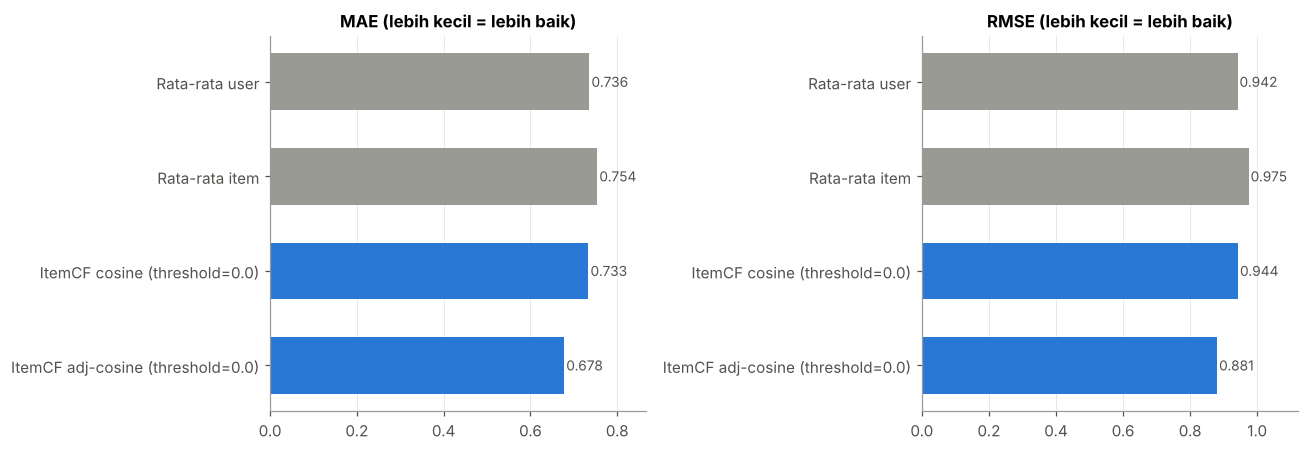

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
for a, m in zip(ax, ["MAE", "RMSE"]):
    vals = res_final[m]
    cols = [BLUE if n.startswith("ItemCF") else GRAY for n in vals.index]
    bars = a.barh(vals.index[::-1], vals.values[::-1], color=cols[::-1], height=0.6)
    for b, v in zip(bars, vals.values[::-1]):
        a.text(v + 0.005, b.get_y() + b.get_height() / 2, f"{v:.3f}", va="center", color=INK2, fontsize=9)
    a.set(title=m + " (lebih kecil = lebih baik)", xlim=(0, vals.max() * 1.15)); a.grid(axis="y", visible=False)
plt.tight_layout(); plt.savefig("fig_i02_itemCF_vs_baseline.png", dpi=200, bbox_inches="tight"); plt.show()

## 6. Top-N & NDCG

Hasil utama memakai gain linear (rating apa adanya), sesuai contoh hitung acuan. Gain biner (rating ≥ 4) dilaporkan berdampingan. Yang diurutkan adalah film test milik tiap user. Hanya user dengan minimal 2 film test yang dihitung, skor peringkat memakai prediksi sebelum dipotong, dan skor yang sama diurutkan secara acak.

In [12]:
def dcg(rels):
    rels = np.asarray(rels, float)
    return float(np.sum(rels / np.log2(np.arange(2, len(rels) + 2))))

def ndcg_at_n(y_true, y_score, n, gain="linear", thr=REL_THRESHOLD, rng=None):
    y_true, y_score = np.asarray(y_true, float), np.asarray(y_score, float)
    rel = y_true if gain == "linear" else (y_true >= thr).astype(float)
    tie = rng.random(len(y_score)) if rng is not None else np.zeros(len(y_score))
    order = np.lexsort((tie, -y_score))                 # skor menurun; seri dipecah acak
    d, ideal = dcg(rel[order][:n]), dcg(np.sort(rel)[::-1][:n])
    return np.nan if ideal == 0 else d / ideal

# cek contoh hitungan rujukan (DCG6 = 6.861, IDCG6 = 7.141, nDCG6 = 0.961)
d, ideal = dcg([3, 2, 3, 0, 1, 2]), dcg([3, 3, 2, 2, 1, 0])
print(f"DCG6={d:.3f}  IDCG6={ideal:.3f}  nDCG6={d/ideal:.3f}   <- acuan: 6.861, 7.141, 0.961")
assert abs(d - 6.861) < 1e-3 and abs(ideal - 7.141) < 1e-3

def eval_ndcg(test_df, scores, ns=N_LIST, seed=SEED):
    # NDCG rata-rata per user atas item test; hanya user dengan >= 2 item test
    rng = np.random.default_rng(seed)
    d = pd.DataFrame({"u": test_df.u.values, "y": test_df.rating.values, "s": np.asarray(scores, float)})
    acc = {(n, g): [] for n in ns for g in ("linear", "binary")}
    for u, g in d.groupby("u"):
        if len(g) < 2:
            continue
        for n in ns:
            for gain in ("linear", "binary"):
                acc[(n, gain)].append(ndcg_at_n(g.y.values, g.s.values, n, gain, rng=rng))
    res = {}
    for (n, gain), v in acc.items():
        v = np.array(v, float)
        res[f"NDCG@{n} ({'linear' if gain == 'linear' else 'biner'})"] = np.nanmean(v)
        res[f"n user ({'linear' if gain == 'linear' else 'biner'}, @{n})"] = int(np.sum(~np.isnan(v)))
    return res

# skor peringkat (sebelum clip) untuk tiap metode
RAW = {}
for name, m in item_models.items():
    RAW[name] = m.predict_pairs(u_te, i_te, clip=False)[0]
RAW["Rata-rata item"] = baselines["Rata-rata item"](u_te, i_te)

ndcg_tbl = pd.DataFrame({k: eval_ndcg(test_df, v) for k, v in RAW.items()}).T
ndcg_cols = [f"NDCG@{n} ({g})" for g in ("linear", "biner") for n in N_LIST]
display(ndcg_tbl[ndcg_cols].round(4))

n_valid     = int(ndcg_tbl.loc[list(ITEM_MODELS)[0], f"n user (linear, @{N_LIST[0]})"])
n_valid_bin = int(ndcg_tbl.loc[list(ITEM_MODELS)[0], f"n user (biner, @{N_LIST[0]})"])
print(f"User dengan >= 2 item test (NDCG linear): {n_valid} dari {N_U} user | dengan >= 1 item relevan (NDCG biner): {n_valid_bin}")
print("Rata-rata user: n/a (prediksi seri untuk semua film milik satu user).")

DCG6=6.861  IDCG6=7.141  nDCG6=0.961   <- acuan: 6.861, 7.141, 0.961


,NDCG@5 (linear),NDCG@10 (linear),NDCG@5 (biner),NDCG@10 (biner)
ItemCF cosine,0.8210,0.8552,0.6485,0.6919
ItemCF adj-cosine,0.8686,0.8961,0.7518,0.7823
Rata-rata item,0.8792,0.9029,0.7749,0.8000


User dengan >= 2 item test (NDCG linear): 603 dari 610 user | dengan >= 1 item relevan (NDCG biner): 588
Rata-rata user: n/a (prediksi seri untuk semua film milik satu user).


### 6.1 Cek dengan soal Kuis 2

Enam film milik satu user, dengan rating asli `r` dan prediksi tiga algoritma (A, B, C). Film relevan bila rating ≥ 4. Hasil MAE, RMSE, dan NDCG dari soal ini dipakai untuk memastikan fungsi di notebook ini menghitung dengan benar.

In [13]:
quiz = pd.DataFrame({"item": [21, 198, 14, 78, 35, 95], "r": [4, 5, 3, 4, 1, 3],
                     "A": [4.1, 3.9, 4.2, 4.9, 2.1, 4.0], "B": [3.3, 4.5, 2.3, 3.5, 1.2, 3.1],
                     "C": [4.9, 4.1, 2.1, 3.1, 2.2, 2.4]})
out = {}
for alg in "ABC":
    m = rating_metrics(quiz.r, quiz[alg], r_min=1, r_max=5)
    out[alg] = {"MAE": m["MAE"], "RMSE": m["RMSE"],
                "NDCG biner (r>=4)": ndcg_at_n(quiz.r, quiz[alg], 6, "binary"),
                "NDCG linear": ndcg_at_n(quiz.r, quiz[alg], 6, "linear")}
display(pd.DataFrame(out).T.round(4))

,MAE,RMSE,NDCG biner (r>=4),NDCG linear
A,0.90,0.9730,0.8855,0.9305
B,0.45,0.5050,1.0000,1.0000
C,0.90,0.9165,1.0000,0.9651


## 7. Contoh rekomendasi Top-N

Kandidat adalah film yang belum dirating user, baik di train maupun di test. Tiap kandidat diprediksi dengan rumus yang sama seperti di bagian 3, diurutkan menurun, lalu dipotong N. Film hanya masuk daftar kalau prediksinya memakai minimal `MIN_NEIGH_TOPN` film mirip. Di ItemCF, "film mirip" berarti film yang sudah dirating user ini dan mirip dengan film kandidat.

Contoh memakai `DEMO_MODEL`. Ditampilkan juga 5 film yang paling mirip dengan film favorit user (kolom `sim`). `skor_mentah` adalah dasar pengurutan sebelum dipotong, dan `pred` adalah `skor_mentah` yang dipotong ke [0,5; 5].

In [14]:
def similar_items(model, item, n=5):
    s = model.sim[item]
    top = np.argsort(-s)[:n]; top = top[s[top] > model.threshold]
    return pd.DataFrame({"film mirip": [title_of(j) for j in top], "genres": [genres_of(j) for j in top], "sim": s[top]})

demo_model = item_models[DEMO_MODEL]
seen_all = ratings.groupby("u").i.apply(set)           # semua film yang pernah dirating user (train + test)
train_cnt = train_df.groupby("u").size()
topn_item = {}
for raw_id in DEMO_USER_IDS:
    if raw_id not in uid:
        print(f"userId {raw_id} tidak ada di data; dilewati"); continue
    u = uid[raw_id]
    print("=" * 100)
    print(f"userId {raw_id} (index {u}) | {train_cnt[u]} rating di train | mean = {demo_model.user_mean[u]:.2f}")
    fav = train_df[train_df.u == u].assign(n=lambda d: item_cnt_train[d.i.values]).sort_values(["rating", "n"], ascending=False).head(5)
    print("Film yang paling disukai (train):")
    for _, r in fav.iterrows():
        print(f"   {r.rating:.1f}  {title_of(int(r.i))}")

    top_fav = int(fav.iloc[0].i)
    print(f"\nFilm paling mirip dengan '{title_of(top_fav)}' ({DEMO_MODEL}):")
    display(similar_items(demo_model, top_fav).round(3))

    rec_i = demo_model.recommend(u, N=5, exclude_items=seen_all[u], min_neigh=MIN_NEIGH_TOPN)
    rec_i["title"] = rec_i.i.map(title_of); rec_i["genres"] = rec_i.i.map(genres_of)
    n_tie = int((demo_model.recommend(u, N=N_I, exclude_items=seen_all[u], min_neigh=MIN_NEIGH_TOPN)
                 .pred_unclipped >= rec_i.pred_unclipped.iloc[-1] - 1e-9).sum())
    print(f"Top-5 ({DEMO_MODEL}, threshold={demo_model.threshold}, min tetangga={MIN_NEIGH_TOPN}); skor_mentah = dasar pengurutan:")
    if n_tie > len(rec_i):
        print(f"  Catatan: {n_tie} kandidat punya skor >= skor peringkat {len(rec_i)}; urutan di antara yang seri hanya mengikuti indeks film.")
    display(rec_i.rename(columns={"pred_unclipped": "skor_mentah"})[["title", "genres", "skor_mentah", "pred", "n_neighbors"]].round(2).reset_index(drop=True))
    topn_item[raw_id] = rec_i

userId 43 (index 42) | 96 rating di train | mean = 4.56
Film yang paling disukai (train):
   5.0  Forrest Gump (1994)
   5.0  Terminator 2: Judgment Day (1991)
   5.0  Toy Story (1995)
   5.0  Apollo 13 (1995)
   5.0  Batman (1989)

Film paling mirip dengan 'Forrest Gump (1994)' (ItemCF cosine):


,film mirip,genres,sim
0,"Deaths of Ian Stone, The (2007)",Horror|Thriller,1.0
1,"Man and a Woman, A (Un homme et une femme) (1966)",Drama|Romance,1.0
2,"Russians Are Coming, the Russians Are Coming, ...",Comedy|War,1.0
3,Red Sorghum (Hong gao liang) (1987),Drama|War,1.0
4,Where the Day Takes You (1992),Drama,1.0


Top-5 (ItemCF cosine, threshold=0.0, min tetangga=5); skor_mentah = dasar pengurutan:
  Catatan: 118 kandidat punya skor >= skor peringkat 5; urutan di antara yang seri hanya mengikuti indeks film.


,title,genres,skor_mentah,pred,n_neighbors
0,Zookeeper (2011),Comedy,5.0,5.0,6
1,Sunset Park (1996),Drama,5.0,5.0,8
2,Head Above Water (1996),Comedy|Thriller,5.0,5.0,5
3,"Boys, The (1998)",Drama,5.0,5.0,5
4,Maurice (1987),Drama|Romance,5.0,5.0,10


## 8. Ringkasan hasil

In [15]:
final = res_final.copy()
for c in ndcg_cols:
    final[c] = np.nan
for key, row in ROW.items():
    if key in ndcg_tbl.index:
        final.loc[row, ndcg_cols] = ndcg_tbl.loc[key, ndcg_cols].values
show = final.drop(columns=["konfigurasi"]).round(4)
display(show.fillna("n/a"))

final.round(4).to_csv("hasil_ringkasan_itemcf.csv")

print("\nParameter yang dipakai")
print(f"  threshold similarity = {SIM_THRESHOLD}")
print(f"  split {int((1-TEST_SIZE)*100)}/{int(TEST_SIZE*100)} seed {SEED} | NMSE = MSE / ({R_MAX} - {R_MIN})")
print(f"  N = {N_LIST} | ambang relevansi = {REL_THRESHOLD} | min tetangga Top-N = {MIN_NEIGH_TOPN}")
print("  coverage: " + " | ".join(f"{n} {(NN[n] > 0).mean()*100:.1f}%" for n in ITEM_MODELS))
print(f"  user valid NDCG = {n_valid} dari {N_U} (linear), {n_valid_bin} (biner)")

,MAE,MSE,RMSE,NMSE,coverage,NDCG@5 (linear),NDCG@10 (linear),NDCG@5 (biner),NDCG@10 (biner)
Rata-rata user,0.7357,0.8877,0.9422,0.1973,n/a,n/a,n/a,n/a,n/a
Rata-rata item,0.7539,0.9514,0.9754,0.2114,n/a,0.8792,0.9029,0.7749,0.8
ItemCF cosine (threshold=0.0),0.7335,0.8905,0.9437,0.1979,0.9604,0.821,0.8552,0.6485,0.6919
ItemCF adj-cosine (threshold=0.0),0.6776,0.7769,0.8814,0.1726,0.9602,0.8686,0.8961,0.7518,0.7823



Parameter yang dipakai
  threshold similarity = 0.0
  split 80/20 seed 42 | NMSE = MSE / (5.0 - 0.5)
  N = [5, 10] | ambang relevansi = 4.0 | min tetangga Top-N = 5
  coverage: ItemCF cosine 96.0% | ItemCF adj-cosine 96.0%
  user valid NDCG = 603 dari 610 (linear), 588 (biner)


## Catatan

* Definisi mengacu pada materi M03 dan Jannach dkk. (2010): cosine dan adjusted cosine atas user yang merating kedua film, prediksi rata-rata berbobot, dan threshold similarity.
* Ukuran split 80.669 / 20.167 diperiksa di sel split. Threshold bernilai 0.
* Prediksi memakai rata-rata user kalau tidak ada film mirip (persentasenya, yaitu 1 − coverage, ikut dilaporkan), prediksi dipotong ke [0,5; 5], dan Top-N butuh minimal film mirip.
* Dua film yang kebetulan dirating oleh satu user yang sama bisa punya cosine tinggi, jadi hasil untuk film yang jarang dirating (sparsity, cold item) harus dibaca hati-hati.
* Keterbatasan: matriks similarity berukuran n × n dan besar karena film jauh lebih banyak daripada user; NDCG hanya mengurutkan film test milik user; satu split 80/20 hanya memberi satu angka.
* Selisih antar model tidak diuji secara statistik, jadi selisih kecil tidak boleh dibaca sebagai satu model jauh lebih baik.